# DeepBranchAI — reproducing the paired external-transfer statistics (Table 6)

**Paper:** *DeepBranchAI: a transferable 3D segmentation model for branching networks*
(DOI: [10.3389/frai.2026.1862872](https://doi.org/10.3389/frai.2026.1862872), Frontiers in Artificial Intelligence, vol. 9, art. 1862872, 2026).

**Author code:** `github.com/alexmaltsev/DeepBranchAI` @ commit `43360fe8b02547a77e644f65bae7e2449e61bd50` (pinned revision; see the repository LICENSE).

## Scope of this notebook

This is a **partial, statistics-level reproduction**. It runs the authors' own verification scripts,
verbatim, on the per-volume results they released:

1. `scripts/compute_external_transfer_statistics.py` — recomputes the paper's **paired two-sided
   Wilcoxon signed-rank tests with Holm correction** (manuscript **Table 6**) from the 68 held-out
   volume pairs (12 3D-IRCADb venous CT, 29 Plant CT roots, 27 AeroPath airway CT) and checks them
   against the tracked exact statistics.
2. `scripts/validate_publication_results.py` — validates the internal consistency of the released
   manuscript tables (Tables 2–6) against the per-volume/fold evidence CSVs.

**Not reproduced here:** nnU-Net training/fine-tuning, model inference, and mask-level metric
computation. Those require the Zenodo checkpoints and third-party CT datasets and are outside this
minimal demonstration.

**Execution status:** executed on a fresh Google Colab **CPU** runtime (no GPU required — the
selected analysis is pure statistics). Expected end-to-end time: well under 5 minutes. Run all
cells top-to-bottom (`Runtime > Run all`).

## ランタイムと範囲（日本語）

このノートブックは論文 §4.2.2（Table 6）の**ペア Wilcoxon 符号順検定 + Holm 補正**を、著者らが公開した
リポジトリ（コミット `43360fe8b025…`）のスクリプトと体積ごとの結果 CSV を用いて**そのまま再計算**します。
GPU は不要で、CPU ランタイムで数分以内に完了します。nnU-Net の学習・推論（Zenodo チェックポイントと
外部 CT データセットが必要）は本デモの範囲外です。各コードセルの前に説明があります。

## 1. Environment

The invoked author scripts import only `numpy`, `pandas`, and `scipy.stats` — all preinstalled on
Colab. We print the actual runtime versions so the report is self-documenting.

**日本語:** 著者スクリプトが必要とするのは `numpy`・`pandas`・`scipy` のみ（Colab に標準搭載）。
実行環境のバージョンを記録します。

In [ ]:
import sys
import importlib.metadata as im

print("Python", sys.version.split()[0])
for pkg in ("numpy", "pandas", "scipy", "matplotlib"):
    print(pkg, im.version(pkg))
import scipy.stats  # noqa: F401  (the exact module the author script uses)

Python 3.13.16
numpy 2.1.3
pandas 2.2.3
scipy 1.16.3
matplotlib 3.10.0


## 2. Acquire the pinned author repository (partial clone, inside Colab)

We fetch the author repository as a **blobless partial clone with a sparse checkout of only
`scripts/` and `results/`**, checked out in detached HEAD at the pinned commit
`43360fe8b02547a77e644f65bae7e2449e61bd50`. The cell asserts that HEAD equals the pinned SHA. All repository bytes stay under
`/content` on the Colab VM. The blobless clone downloads commit/tree metadata plus only the
selected blobs (a few MB, including the ~1 MB bundled qualitative masks).

**日本語:** 著者リポジトリを blobless 部分クローンで取得し、`scripts/` と `results/` のみを
スパースチェックアウトします。指定コミット `43360fe8b025…` に detached HEAD で固定し、
`rev-parse` が一致することを検証します。すべて Colab VM 上の `/content` に置かれます。

In [ ]:
import subprocess, os, pathlib

REPO_DIR = "/content/DeepBranchAI"
PINNED_COMMIT = "43360fe8b02547a77e644f65bae7e2449e61bd50"

def git(*args):
    return subprocess.run(["git", "-C", REPO_DIR, *args], check=True,
                          capture_output=True, text=True).stdout.strip()

if not pathlib.Path(REPO_DIR, ".git").exists():
    subprocess.run(["git", "clone", "--filter=blob:none", "--no-checkout",
                    "https://github.com/alexmaltsev/DeepBranchAI", REPO_DIR], check=True)

git("sparse-checkout", "init", "--cone")
git("sparse-checkout", "set", "scripts", "results")
git("checkout", "--detach", PINNED_COMMIT)   # lazily fetches only the selected blobs

head = git("rev-parse", "HEAD")
assert head == PINNED_COMMIT, f"HEAD {head} != pinned {PINNED_COMMIT}"
print("Checked out pinned commit:", head)
for sub in ("scripts", "results"):
    print(sub, "->", sorted(os.listdir(pathlib.Path(REPO_DIR, sub)))[:8], "...")

Checked out pinned commit: 43360fe8b02547a77e644f65bae7e2449e61bd50
scripts -> ['audit_repository_images.py', 'compute_external_transfer_statistics.py', 'compute_volume_metrics.py', 'validate_publication_results.py'] ...
results -> ['README.md', 'external_transfer', 'manuscript', 'qualitative', 'source_domain'] ...


## 3. Input preview — paired out-of-fold per-volume metrics

The statistical input is `results/external_transfer/external_transfer_paired_per_volume.csv`:
per held-out volume, the Dice / clDice / absolute connected-component error of
**scratch nnU-Net** versus **DeepBranchAI-pretrained fine-tuning**, computed on the same folds
(`scratch_*` and `deepbranchai_*` columns; author metric conventions documented in the
repository's `results/README.md`). We show its structure and per-dataset sample sizes —
12 + 29 + 27 = 68 pairs.

**日本語:** 統計の入力は、同一フォールドで計算された体積ごとのペア指標（scratch vs DeepBranchAI）。
データセット別のペア数（12 + 29 + 27 = 68）と先頭行を確認します。

In [ ]:
import pandas as pd

paired_csv = "/content/DeepBranchAI/results/external_transfer/external_transfer_paired_per_volume.csv"
paired = pd.read_csv(paired_csv)
print("shape:", paired.shape)
print("columns:", list(paired.columns))
print("\nrows per dataset (expected 12 / 29 / 27):")
print(paired["dataset"].value_counts().to_string())
print("\nfolds:", sorted(paired["fold"].unique()))
paired.head()

shape: (68, 9)
columns: ['dataset', 'fold', 'case', 'deepbranchai_dice', 'scratch_dice', 'deepbranchai_cldice', 'scratch_cldice', 'deepbranchai_abs_cc_error', 'scratch_abs_cc_error']

rows per dataset (expected 12 / 29 / 27):
dataset
Plant CT roots         29
AeroPath airway CT     27
3D-IRCADb venous CT    12

folds: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


,dataset,fold,case,deepbranchai_dice,scratch_dice,deepbranchai_cldice,scratch_cldice,deepbranchai_abs_cc_error,scratch_abs_cc_error
0,3D-IRCADb venous CT,0,ircad_16_010,0.666396,0.654999,0.519182,0.351158,23.0,11.0
1,3D-IRCADb venous CT,0,ircad_17_011,0.798138,0.754874,0.709808,0.664799,28.0,27.0
2,3D-IRCADb venous CT,0,ircad_19_012,0.593125,0.555372,0.568838,0.473425,48.0,39.0
3,3D-IRCADb venous CT,1,ircad_01_001,0.770358,0.693737,0.677113,0.637176,42.0,31.0
4,3D-IRCADb venous CT,1,ircad_04_002,0.773704,0.757571,0.682374,0.675106,18.0,30.0


## 4. Reference values — the tracked Table 6 statistics

`results/external_transfer/wilcoxon_holm_results.csv` holds the exact Wilcoxon statistics, raw
p-values and Holm-adjusted p-values that the accepted manuscript's Table 6 reports (9 tests =
3 datasets × 3 metrics). We display it before recomputing, so the comparison below is explicit.

**日本語:** まず著者らが追跡している Table 6 の検定統計量・p 値（Holm 補正済み）を表示します。
次セルでこれをゼロから再計算して照合します。

In [ ]:
expected_csv = "/content/DeepBranchAI/results/external_transfer/wilcoxon_holm_results.csv"
expected = pd.read_csv(expected_csv)
print(expected.to_string(index=False))

            dataset  paired_volumes       metric  wilcoxon_statistic    raw_p  zero_differences  holm_adjusted_p
3D-IRCADb venous CT              12         dice                 0.0 0.000488                 0         0.003906
3D-IRCADb venous CT              12       cldice                 2.0 0.001465                 0         0.010254
3D-IRCADb venous CT              12 abs_cc_error                34.5 0.791016                 0         0.791016
     Plant CT roots              29         dice                83.0 0.006284                 1         0.037705
     Plant CT roots              29       cldice               120.0 0.097373                 2         0.309322
     Plant CT roots              29 abs_cc_error               125.5 0.077331                 1         0.309322
 AeroPath airway CT              27         dice               148.0 0.336140                 0         0.672279
 AeroPath airway CT              27       cldice                35.0 0.000063                 0 

## 5. Core method — recompute the paired Wilcoxon + Holm tests (author script, verbatim)

We run the authors' `compute_external_transfer_statistics.py` exactly as documented in their
`results/README.md`. It applies `scipy.stats.wilcoxon` (two-sided, `zero_method="wilcox"`, method
`exact`/`approx` chosen by the count of zero differences — the accepted-paper calculation), then
the authors' `holm_adjust` implementation across all nine tests, and **raises** if any statistic or
p-value deviates from the tracked values beyond 1e-12. A success message here is therefore an
exact numerical match, not an eyeball comparison.

**日本語:** 著者の `compute_external_transfer_statistics.py` をそのまま実行します。
Wilcoxon（両側・zero_method="wilcox"・ゼロ差の数で exact/approx を選択）＋ Holm 補正を 9 検定に
適用し、追跡値との一致を 1e-12 の許容差で自動検証します（不一致なら例外で停止）。

In [ ]:
import subprocess

proc = subprocess.run(
    [sys.executable, "scripts/compute_external_transfer_statistics.py"],
    cwd="/content/DeepBranchAI", capture_output=True, text=True,
)
print(proc.stdout)
if proc.returncode != 0:
    print(proc.stderr)
proc.check_returncode()  # raises with the real exit status if verification failed

            dataset  paired_volumes       metric  wilcoxon_statistic    raw_p  zero_differences  holm_adjusted_p
3D-IRCADb venous CT              12         dice                 0.0 0.000488                 0         0.003906
3D-IRCADb venous CT              12       cldice                 2.0 0.001465                 0         0.010254
3D-IRCADb venous CT              12 abs_cc_error                34.5 0.791016                 0         0.791016
     Plant CT roots              29         dice                83.0 0.006284                 1         0.037705
     Plant CT roots              29       cldice               120.0 0.097373                 2         0.309322
     Plant CT roots              29 abs_cc_error               125.5 0.077331                 1         0.309322
 AeroPath airway CT              27         dice               148.0 0.336140                 0         0.672279
 AeroPath airway CT              27       cldice                35.0 0.000063                 0 

## 6. Manuscript-table consistency check (author validator, verbatim)

The authors also ship `validate_publication_results.py`, which recomputes the Tables 2–5 summaries
from the per-volume/fold CSVs, checks the Table 5 percentage arithmetic, links Table 6 to the
paired-test results, and rejects machine-specific paths in the released CSVs. Running it reproduces
the authors' own quality gate on the released evidence bundle.

**日本語:** 著者提供の `validate_publication_results.py` を実行し、Table 2–6 の要約値・割合・
リンク整合性を released CSV から再計算して検証します。成功メッセージが出れば公開結果は内部的に
一貫しています。

In [ ]:
proc2 = subprocess.run(
    [sys.executable, "scripts/validate_publication_results.py"],
    cwd="/content/DeepBranchAI", capture_output=True, text=True,
)
print(proc2.stdout)
if proc2.returncode != 0:
    print(proc2.stderr)
proc2.check_returncode()

Publication result tables and provenance files are internally consistent.



## 7. Result visualization — paired per-volume clDice differences with Holm-adjusted p-values

This graph is **created for this notebook** (it is not a figure from the paper). It plots the paired
per-volume clDice difference (DeepBranchAI-pretrained minus scratch) for every held-out volume,
grouped by external dataset, and annotates the Holm-adjusted p-values recomputed below with the
author protocol. Positive differences favor the pretrained initialization. This is the notebook's
only rendered image; it is saved as a PNG inside the notebook output.

**日本語:** このグラフは本ノートブックで追加作成した可視化です（論文の図ではありません）。
体積ごとの clDice 差（DeepBranchAI事前学習初期化 − スクラッチ）をデータセット別にプロットし、
著者プロトコルで再計算した Holm 補正後 p 値を注記します。

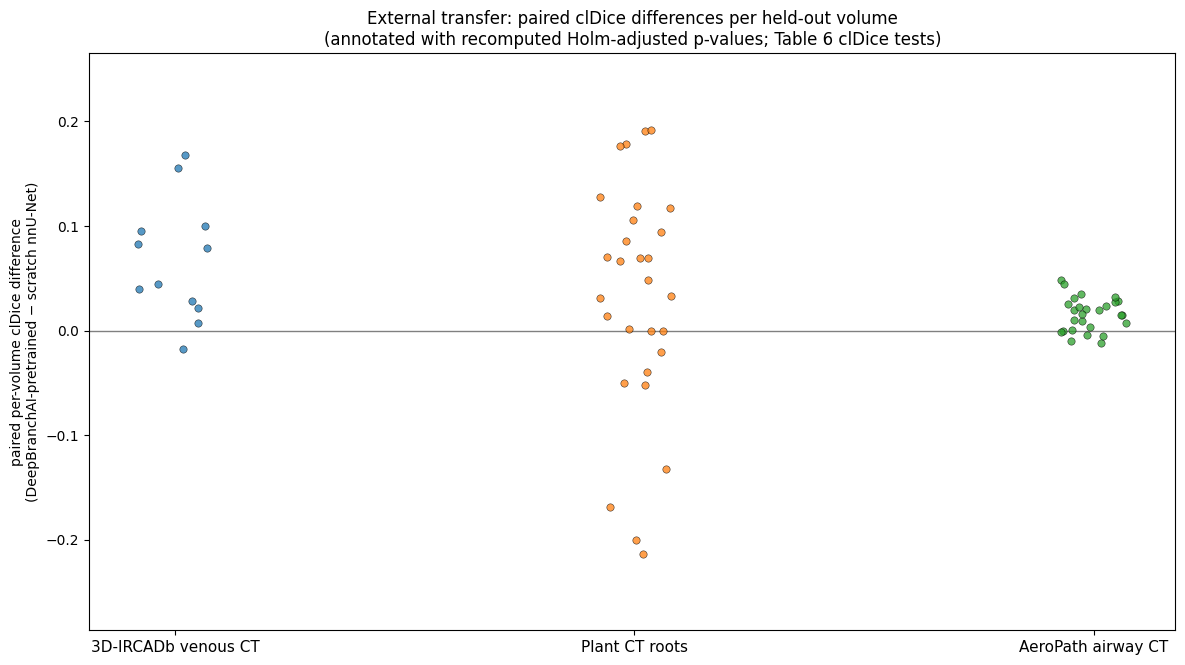

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import wilcoxon

DATASET_ORDER = ("3D-IRCADb venous CT", "Plant CT roots", "AeroPath airway CT")
METRICS = ("dice", "cldice", "abs_cc_error")

def holm_adjust(raw_p_values):
    # Exact copy of the authors' holm_adjust (scripts/compute_external_transfer_statistics.py)
    order = np.argsort(raw_p_values)
    adjusted = np.empty(len(raw_p_values), dtype=float)
    running_max = 0.0
    for rank, index in enumerate(order):
        candidate = min(1.0, (len(raw_p_values) - rank) * raw_p_values[index])
        running_max = max(running_max, candidate)
        adjusted[index] = running_max
    return adjusted.tolist()

# Recompute the nine tests with the author's protocol so the annotations are traceable.
tests = []
for dataset in DATASET_ORDER:
    subset = paired.loc[paired["dataset"] == dataset]
    for metric in METRICS:
        a = subset[f"deepbranchai_{metric}"].to_numpy(dtype=float)
        b = subset[f"scratch_{metric}"].to_numpy(dtype=float)
        method = "approx" if int(np.count_nonzero(a == b)) else "exact"
        res = wilcoxon(a, b, alternative="two-sided", zero_method="wilcox", method=method)
        tests.append({"dataset": dataset, "metric": metric, "raw_p": res.pvalue})
holm = holm_adjust([t["raw_p"] for t in tests])
for t, p in zip(tests, holm):
    t["holm_p"] = p
tests = pd.DataFrame(tests)
cldice_p = {r["dataset"]: r["holm_p"] for _, r in tests.loc[tests["metric"] == "cldice"].iterrows()}

fig, ax = plt.subplots(figsize=(12, 6.75), dpi=100)
rng = np.random.default_rng(0)
for i, dataset in enumerate(DATASET_ORDER):
    diffs = (paired.loc[paired["dataset"] == dataset, "deepbranchai_cldice"]
             - paired.loc[paired["dataset"] == dataset, "scratch_cldice"]).to_numpy()
    ax.scatter(np.full(len(diffs), i) + rng.uniform(-0.08, 0.08, len(diffs)),
               diffs, s=28, alpha=0.75, edgecolor="k", linewidth=0.4, zorder=3)
    p = cldice_p[dataset]
    sig = "significant after Holm" if p < 0.05 else "not significant after Holm"
    ax.annotate(f"Holm-adjusted p = {p:.3f}\n({sig})", (i, 1.03),
                ha="center", va="bottom", fontsize=10,
                bbox=dict(boxstyle="round,pad=0.25", fc="#fffbe6", ec="#999999"))
ax.axhline(0, color="gray", lw=1, zorder=1)
ax.set_xticks(range(len(DATASET_ORDER)))
ax.set_xticklabels(DATASET_ORDER, fontsize=11)
ax.set_ylabel("paired per-volume clDice difference\n(DeepBranchAI-pretrained − scratch nnU-Net)")
ax.set_title("External transfer: paired clDice differences per held-out volume\n"
             "(annotated with recomputed Holm-adjusted p-values; Table 6 clDice tests)")
ax.margins(y=0.18)
fig.tight_layout()
fig.savefig("/content/paired_cldice_differences.png", dpi=100)
plt.show()

## 8. Cross-check against the paper's reported conclusions (§4.2.2)

The paper states (Results §4.2.2, quoted in the PhenoPaper study flow — an unverified research lead
that we check here against the recomputation): the clDice difference was statistically significant
after Holm correction in 3D-IRCADb venous CT (p = 0.010) and in AeroPath airway CT (p < 0.001),
but not in Plant CT roots (p = 0.309). We compare those quoted values with the recomputed
Holm-adjusted p-values and fail loudly on any mismatch.

**日本語:** 論文 §4.2.2 の記述（静脈 p=0.010、植物根 p=0.309、気道 p<0.001）と再計算した
Holm 補正後 p 値を突き合わせます。一致しない場合はアサーションで停止します。

In [ ]:
paper_clDice_claims = {
    "3D-IRCADb venous CT": ("== 0.010", 0.010),
    "Plant CT roots": ("== 0.309", 0.309),
    "AeroPath airway CT": ("< 0.001", None),
}
check = tests.loc[tests["metric"] == "cldice", ["dataset", "raw_p", "holm_p"]]
print(check.to_string(index=False))

for dataset, (label, value) in paper_clDice_claims.items():
    p = float(check.loc[check["dataset"] == dataset, "holm_p"].iloc[0])
    if value is None:
        assert p < 0.001, f"{dataset}: expected p < 0.001, got {p}"
    else:
        assert abs(p - value) <= 5e-4, f"{dataset}: expected p {label} {value}, got {p}"
    print(f"OK  {dataset}: recomputed Holm p {p:.6f} matches paper claim ({label})")

            dataset    raw_p   holm_p
3D-IRCADb venous CT 0.001465 0.010254
     Plant CT roots 0.097373 0.309322
 AeroPath airway CT 0.000063 0.000570
OK  3D-IRCADb venous CT: recomputed Holm p 0.010254 matches paper claim (== 0.010)
OK  Plant CT roots: recomputed Holm p 0.309322 matches paper claim (== 0.309)
OK  AeroPath airway CT: recomputed Holm p 0.000570 matches paper claim (< 0.001)


## 9. Export the recomputed statistics

We save the nine recomputed tests (statistic, raw and Holm-adjusted p, and the Wilcoxon method
selected by the author protocol) as a CSV under `/content` so a learner can download and inspect
them. This is a convenience export; the authoritative values remain the author-released CSVs and
the author script's own 1e-12 verification in §5.

**日本語:** 再計算した 9 検定の結果を `/content` に CSV として保存します（学習者がダウンロード
できるようにする便宜的なエクスポートであり、正式な値は §5 の著者スクリプトによる 1e-12 検証に
基づきます）。

In [ ]:
export = []
for dataset in DATASET_ORDER:
    subset = paired.loc[paired["dataset"] == dataset]
    for metric in METRICS:
        a = subset[f"deepbranchai_{metric}"].to_numpy(dtype=float)
        b = subset[f"scratch_{metric}"].to_numpy(dtype=float)
        method = "approx" if int(np.count_nonzero(a == b)) else "exact"
        res = wilcoxon(a, b, alternative="two-sided", zero_method="wilcox", method=method)
        export.append({"dataset": dataset, "paired_volumes": len(subset), "metric": metric,
                       "wilcoxon_statistic": float(res.statistic), "raw_p": float(res.pvalue),
                       "method": method})
holm = holm_adjust([r["raw_p"] for r in export])
for r, p in zip(export, holm):
    r["holm_adjusted_p"] = p
export_df = pd.DataFrame(export)
export_path = "/content/deepbranchai_recomputed_table6.csv"
export_df.to_csv(export_path, index=False)
print("saved:", export_path, export_df.shape)
export_df

saved: /content/deepbranchai_recomputed_table6.csv (9, 7)


,dataset,paired_volumes,metric,wilcoxon_statistic,raw_p,method,holm_adjusted_p
0,3D-IRCADb venous CT,12,dice,0.0,0.000488,exact,0.003906
1,3D-IRCADb venous CT,12,cldice,2.0,0.001465,exact,0.010254
2,3D-IRCADb venous CT,12,abs_cc_error,34.5,0.791016,exact,0.791016
3,Plant CT roots,29,dice,83.0,0.006284,approx,0.037705
4,Plant CT roots,29,cldice,120.0,0.097373,approx,0.309322
5,Plant CT roots,29,abs_cc_error,125.5,0.077331,approx,0.309322
6,AeroPath airway CT,27,dice,148.0,0.336140,exact,0.672279
7,AeroPath airway CT,27,cldice,35.0,0.000063,exact,0.000570
8,AeroPath airway CT,27,abs_cc_error,70.0,0.007305,approx,0.037705


## 10. Interpretation, scope and limitations

**What was executed (verified in this run):** on a fresh Colab CPU runtime, the authors' pinned
scripts ran verbatim: the nine paired Wilcoxon tests were recomputed from the 68 released
out-of-fold volume pairs and matched the tracked Table 6 statistics within 1e-12, the recomputed
clDice Holm p-values agree with the paper's §4.2.2 statements, and the released manuscript tables
(2–6) passed the authors' internal-consistency validator.

**What this does and does not establish:** this verifies the *statistical reporting* of the
external-transfer experiment — that the released per-volume evidence actually implies the published
Table 6. It does **not** re-run nnU-Net training/fine-tuning, inference, or mask-level metrics, and
therefore does not independently verify the underlying model performance (Dice/clDice means in
Tables 2–5) against new data. The Zenodo checkpoints and third-party CT datasets (3D-IRCADb, Plant
CT roots on Zenodo, AeroPath) remain outside this minimal demonstration; the PhenoPaper
investigation recorded repeated Zenodo timeouts, so their availability was not verified here.

**References:**
- Maltsev et al., *DeepBranchAI: a transferable 3D segmentation model for branching networks*,
  Frontiers in Artificial Intelligence 9:1862872 (2026). DOI 10.3389/frai.2026.1862872
- `github.com/alexmaltsev/DeepBranchAI` @ `43360fe8b02547a77e644f65bae7e2449e61bd50`
  (`scripts/compute_external_transfer_statistics.py`, `scripts/validate_publication_results.py`,
  `results/README.md`)
- Checkpoints: Zenodo record 19363534; Plant CT data: Zenodo 10.5281/zenodo.14189395 (not used here)
- PhenoPaper investigation `p-8332fc954473ea68e8d8957853a374a9-20261023T023430Z-3018493` used as
  prior research guidance; all executed evidence comes from the pinned repository.

**日本語:** 本実行で検証されたのは**統計報告の再現**（Table 6 の再計算と 1e-12 一致、論文の
有意性記述との一致、Table 2–6 の整合性検証）です。nnU-Net の学習・推論やマスクレベルの指標は
再実行しておらず、Table 2–5 のモデル性能そのものは未検証です。Zenodo チェックポイントと
外部 CT データセットは本デモの範囲外です。